In [9]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
rank_table = pd.read_csv("grouped_metrics_vitlarge_multiskip_imagenet1k.csv")

In [5]:
rank_table.columns

Index(['rank', 'span', 'true_accuracy', 'orig_head_accuracy', 'kl_div',
       'top1_flip_pct', 'entropy_delta', 'cosine_sim', 'mse', 'cka_embed',
       'knn_overlap@5', 'knn_overlap@10', 'participation_ratio_change',
       'local_cka', 'angular_dist'],
      dtype='object')

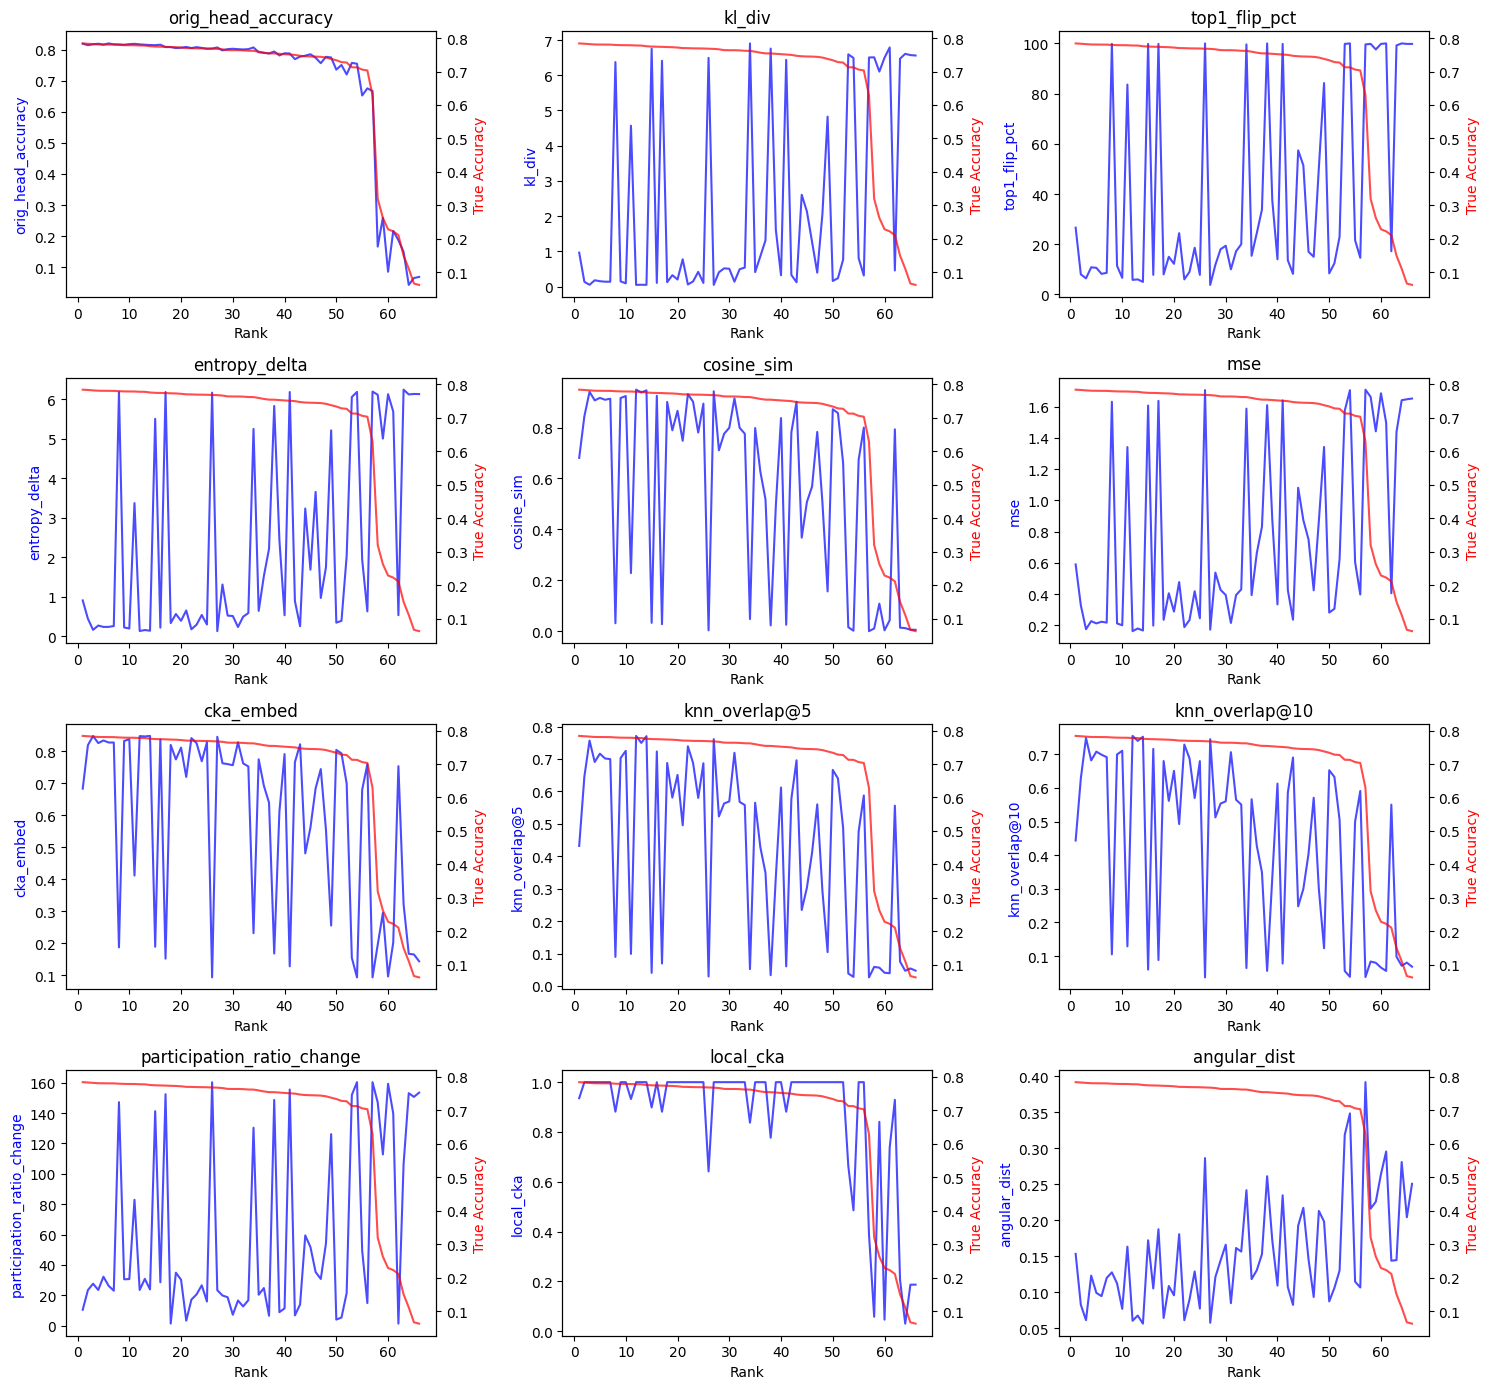

In [ ]:
metrics = list(rank_table.columns[3:])
ncols = 3
nrows = -(-len(metrics) // ncols)  # ceil

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
axes = axes.flatten()

for ax1, metric in zip(axes, metrics):
    ax2 = ax1.twinx()
    ax1.plot(rank_table["rank"], rank_table[metric], color="blue", alpha=0.7, label=metric)
    ax2.plot(rank_table["rank"], rank_table["true_accuracy"], color="red", alpha=0.7, label="True Accuracy")
    ax1.set_xlabel("True Accuracy Rank")
    ax1.set_ylabel(metric, color="blue")
    ax2.set_ylabel("True Accuracy", color="red")
    ax1.set_title(metric)

# hide any unused axes if metrics doesn't evenly fill the grid
for ax in axes[len(metrics):]:
    ax.axis("off")

fig.tight_layout()


12